# Model 1: peak acceleration on one axis

One number per 3 s window: the peak of `ay` (max |ay − mean|).
Each class is a bell curve (Gaussian) with its own mean and spread. A new
window gets the class whose curve is highest at its peak.

1. Load and trim recordings
2. Window peaks
3. The model
4. Blocked 5-fold cross-validation
5. Fit on all data, plot, save `model1.json`

In [6]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
CLASSES = ["still", "bike", "walk", "run"]
AXIS = "ay"
FS = 50
WIN_S = 3.0
TRIM_S = 5.0                      # drop from the start and end of every recording
EXTRA_TRIM_S = {"walk_01": 70.0}  # strap was settling at the start
N_BLOCKS = 5
MIN_SD = 0.01                     # floor on spread so still's tiny spread stays usable

## 1. Load and trim

In [7]:
recs = []   # (name, label, ay values)
for p in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(p)
    t = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    start = TRIM_S + EXTRA_TRIM_S.get(p.stem, 0.0)
    keep = (t >= start) & (t <= t.iloc[-1] - TRIM_S)
    recs.append((p.stem, p.stem.rsplit("_", 1)[0], df.loc[keep, AXIS].to_numpy()))
    print(f"{p.stem:10s} {keep.sum() / FS:6.1f} s kept")

bike_01      69.2 s kept
run_01       53.4 s kept
still_01    114.0 s kept
walk_01     205.4 s kept


## 2. Window peaks

3 s windows with 50% overlap. Each recording is also split into 5 time blocks
for testing; windows that cross a block edge are dropped so no data is shared
between a training block and a test block.

In [8]:
def peak(x):
    return np.abs(x - x.mean()).max()


n = int(WIN_S * FS)
rows = []
for name, label, x in recs:
    block_of = np.arange(len(x)) * N_BLOCKS // len(x)
    for i in range(0, len(x) - n + 1, n // 2):
        if block_of[i] != block_of[i + n - 1]:
            continue
        rows.append({"rec": name, "label": label, "block": block_of[i], "peak": peak(x[i:i + n])})
win = pd.DataFrame(rows)
win.groupby("label").size().reindex(CLASSES)

label
still     67
bike      37
walk     127
run       26
dtype: int64

## 3. The model

Training: mean and spread of the peak for each class.
Predicting: for each class, how likely is this peak under its bell curve?
Pick the most likely one. All classes count equally, even though walk has more
windows.

In [9]:
def fit(df):
    g = df.groupby("label").peak
    return {c: {"mean": float(g.mean()[c]), "sd": max(float(g.std()[c]), MIN_SD)} for c in CLASSES}


def log_likelihood(model, peaks):
    """One column per class: log of the bell curve's height at each peak."""
    peaks = np.asarray(peaks, dtype=float)
    return np.column_stack([
        -np.log(model[c]["sd"]) - 0.5 * ((peaks - model[c]["mean"]) / model[c]["sd"]) ** 2
        for c in CLASSES
    ])


def predict(model, peaks):
    return np.array(CLASSES)[log_likelihood(model, peaks).argmax(axis=1)]

## 4. Blocked 5-fold cross-validation

Each round trains on 4 blocks from every recording and tests on the 5th.

In [10]:
win["pred"] = ""
for b in range(N_BLOCKS):
    test = win.block == b
    model = fit(win[~test])
    win.loc[test, "pred"] = predict(model, win.loc[test, "peak"])

acc = (win.pred == win.label).mean()
recall = (win.pred == win.label).groupby(win.label).mean().reindex(CLASSES)
print(f"Accuracy: {acc:.1%}")
print(f"Balanced accuracy (mean of per-class recall): {recall.mean():.1%}\n")
print("Recall per class (share of each class predicted correctly):")
print(recall.map("{:.1%}".format).to_string())

Accuracy: 95.3%
Balanced accuracy (mean of per-class recall): 97.2%

Recall per class (share of each class predicted correctly):
label
still    100.0%
bike      97.3%
walk      91.3%
run      100.0%


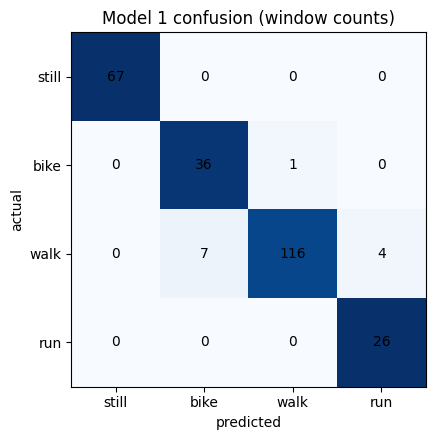

In [11]:
conf = pd.crosstab(win.label, win.pred).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(conf.div(conf.sum(axis=1), axis=0), cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, conf.iloc[i, j], ha="center", va="center")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("Model 1 confusion (window counts)")
fig.tight_layout()

## 5. Fit on all data

In [12]:
model = fit(win)
pd.DataFrame(model).T.round(3)

,mean,sd
still,0.020,0.015
bike,1.132,0.092
walk,1.767,0.311
run,3.540,0.544


In [13]:
# Decision boundaries: peaks where the predicted class changes
grid = np.linspace(0, win.peak.max() * 1.1, 5000)
pred = predict(model, grid)
change = np.nonzero(pred[1:] != pred[:-1])[0]
boundaries = [(float(grid[i]), pred[i], pred[i + 1]) for i in change]
for g, a, b in boundaries:
    print(f"{g:5.2f} g: {a} -> {b}")

 0.11 g: still -> walk
 0.81 g: walk -> bike
 1.33 g: bike -> walk
 2.46 g: walk -> run


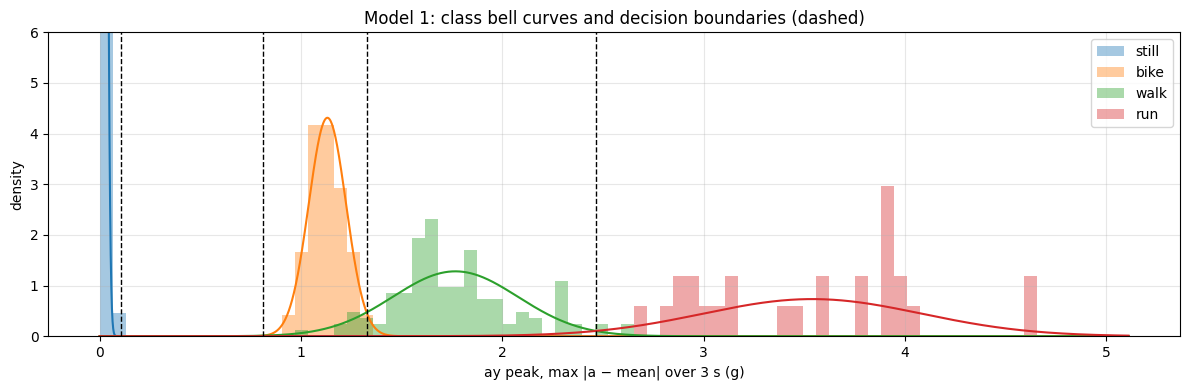

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
bins = np.linspace(0, grid[-1], 80)
colors = dict(zip(CLASSES, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
for c in CLASSES:
    ax.hist(win[win.label == c].peak, bins=bins, density=True, alpha=0.4, color=colors[c], label=c)
    m, s = model[c]["mean"], model[c]["sd"]
    curve = np.exp(-0.5 * ((grid - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
    ax.plot(grid, curve, color=colors[c], lw=1.5)
for g, _, _ in boundaries:
    ax.axvline(g, color="k", ls="--", lw=1)
ax.set_ylim(0, 6)   # still's curve is very tall; clip so the others are visible
ax.set_xlabel(f"{AXIS} peak, max |a − mean| over {WIN_S:.0f} s (g)")
ax.set_ylabel("density")
ax.set_title("Model 1: class bell curves and decision boundaries (dashed)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

In [15]:
out = {
    "axis": AXIS,
    "fs": FS,
    "window_s": WIN_S,
    "feature": "max |a - mean| over the window",
    "classes": model,
    "boundaries": [{"at": round(g, 3), "below": a, "above": b} for g, a, b in boundaries],
    "cv": {"accuracy": round(float(acc), 3),
           "recall": {c: round(float(recall[c]), 3) for c in CLASSES}},
}
Path("model1.json").write_text(json.dumps(out, indent=2))
print(json.dumps(out, indent=2))

{
  "axis": "ay",
  "fs": 50,
  "window_s": 3.0,
  "feature": "max |a - mean| over the window",
  "classes": {
    "still": {
      "mean": 0.020482388059701487,
      "sd": 0.01458300757853745
    },
    "bike": {
      "mean": 1.1316452252252254,
      "sd": 0.09249635212206608
    },
    "walk": {
      "mean": 1.767292965879265,
      "sd": 0.31138315105916115
    },
    "run": {
      "mean": 3.540401538461538,
      "sd": 0.544029154066198
    }
  },
  "boundaries": [
    {
      "at": 0.105,
      "below": "still",
      "above": "walk"
    },
    {
      "at": 0.813,
      "below": "walk",
      "above": "bike"
    },
    {
      "at": 1.326,
      "below": "bike",
      "above": "walk"
    },
    {
      "at": 2.464,
      "below": "walk",
      "above": "run"
    }
  ],
  "cv": {
    "accuracy": 0.953,
    "recall": {
      "still": 1.0,
      "bike": 0.973,
      "walk": 0.913,
      "run": 1.0
    }
  }
}
